# 第IV部：Euler方程式の空間再構築

**問い：同じ数値流束・時間積分で、セル境界の左右状態の作り方は数値解をどう変えるか。**

Roe・LLF (Rusanov)・HLL・HLLCのそれぞれについて、区分一定、MUSCL＋minmod、MUSCL＋MC、制限なし線形再構築を比較します。時間積分はSSP-RK2に固定します。流束ごとに図を分け、空間再構築だけを変えます。

[I 移流・Burgers](01_advection_burgers.ipynb) · [II Eulerの古典的解法](02_euler_classical.ipynb) · [III 数値流束](03_euler_riemann_solvers.ipynb) · [IV 空間再構築](04_spatial_reconstruction.ipynb) · [V 時間積分](05_time_integration.ipynb)

## 0. 設定と実行方法

`notebooks/` と `src/` の配置を保ち、設定セルを確認して上から実行します。
数値流束・初期条件・境界条件・厳密解は `euler1d_core.py`、空間と時間を独立に選ぶ計算は `euler1d_mol.py`、実験・描画は `euler1d_experiments.py` を使用します。
図のラベルは英語、解説は日本語です。物理量はすべて無次元です。
動画は標準で有効です。Shu–Osherの高解像度参照計算は設定で有効にします。
設定を変更したらカーネルを再起動し、全セルを実行してください。

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/euler1d_mol.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("リポジトリ一式の notebooks/ と src/ の配置を保ってください。")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
import euler1d_core as core
import euler1d_mol as mol
import euler1d_experiments as ex
from euler1d_study import show_table, shu_reference

ex.CACHE.clear()
TABLES = {}
reference = None
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)
print("MOL checks:", len(mol.run_tests()))

Python: 3.11.18 NumPy: 2.4.6


MOL checks: 8


### 空間再構築の選択肢

| `spatial_methods` の値 | 再構築 | 主な目的 |
|:--|:--|:--|
| `constant` | 区分一定 | 1次精度の基準 |
| `muscl_minmod` | MUSCL＋minmod | 勾配制限と数値拡散 |
| `muscl_mc` | MUSCL＋MC | リミッターによる差 |
| `linear_unlimited` | 中心勾配を制限せず線形外挿 | 数値振動・負の再構築値の反例 |

`fluxes` の選択肢は `Roe`、`LLF`、`HLL`、`HLLC` です。表示名は **LLF (Rusanov)** です。
`time_integrator` は `forward_euler`、`ssprk2`、`ssprk3` を受け付けますが、この部の基本演習では **`ssprk2`に固定**してください。時間積分の比較は第V部で扱います。
`run_time_check=True` は同じ格子・空間手法でCFL数を半減させ、時間誤差への感度を調べます。

### 動画の選択肢

| `movie_problem` | 内容 |
|:--|:--|
| `entropy` | 滑らかなエントロピー波の移流 |
| `contact` | 移動する接触不連続面 |
| `contact_static` | 静止する接触不連続面 |
| `sod` | Sod衝撃波管 |
| `double_rarefaction` | 二重希薄波。負圧などで停止した方式は停止後に描かない |
| `lax` | Lax衝撃波管 |
| `transonic` | 音速をまたぐ希薄波 |

`movie_fluxes` は `("Roe", "LLF", "HLL", "HLLC")` の一部または全部を指定します。各流束に1本の動画を作ります。標準は `("HLLC",)` です。
`movie_field` は `"rho"`（密度）、`"u"`（速度）、`"p"`（圧力）、`"e"`（比内部エネルギー）です。
`movie_frames` は表示フレーム数であり、数値積分のステップ数ではありません。
`shu_osher` はこの動画機能の対象外です。動画を省略する場合は `run_movies=False` にします。

In [2]:
CFG = {
    "gamma": 1.4,
    "fluxes": ("Roe", "LLF", "HLL", "HLLC"),
    "spatial_methods": ("constant", "muscl_minmod", "muscl_mc", "linear_unlimited"),
    "time_integrator": "ssprk2",  # 空間再構築の比較では固定する
    "n_basic": 200,
    "cfl": 0.4,
    "wave_speeds": "einfeldt",
    "roe_entropy": 0.1,
    "n_convergence": (50, 100, 200, 400),
    "run_convergence": True,
    "run_time_check": True,
    "run_robustness": True,
    "run_extras": False,
    "run_shu_osher": False,
    "n_shu_osher": 400,
    "n_reference": (1600, 3200),
    "reference_limiter": "mc",
    "limiter": "minmod",  # Shu–Osher参照計算の共通設定。比較する制限関数はspatial_methodsで指定
    "run_movies": True,
    "movie_problem": "sod",  # 選択肢は直前の表を参照
    "movie_fluxes": ("HLLC",),
    "movie_field": "rho",
    "movie_frames": 41,
    "export_results": True,
}
ex.validate_config(CFG, "space")
OUTPUT_DIR = ROOT / "five_part_outputs" / "spatial"
print(CFG)

{'gamma': 1.4, 'fluxes': ('Roe', 'LLF', 'HLL', 'HLLC'), 'spatial_methods': ('constant', 'muscl_minmod', 'muscl_mc', 'linear_unlimited'), 'time_integrator': 'ssprk2', 'n_basic': 200, 'cfl': 0.4, 'wave_speeds': 'einfeldt', 'roe_entropy': 0.1, 'n_convergence': (50, 100, 200, 400), 'run_convergence': True, 'run_time_check': True, 'run_robustness': True, 'run_extras': False, 'run_shu_osher': False, 'n_shu_osher': 400, 'n_reference': (1600, 3200), 'reference_limiter': 'mc', 'limiter': 'minmod', 'run_movies': True, 'movie_problem': 'sod', 'movie_fluxes': ('HLLC',), 'movie_field': 'rho', 'movie_frames': 41, 'export_results': True}


## 1. 数値流束・空間再構築・時間積分を分ける

$U=(\rho,\rho u,E)^T$、$F(U)=(\rho u,\rho u^2+p,u(E+p))^T$、$p=(\gamma-1)(E-\rho u^2/2)$とします。
未知量はセル平均 $\bar U_i$ です。境界の左右状態を再構築し、数値流束 $\widehat F$ を求めると、

$$\frac{d\bar U_i}{dt}=\mathcal L(\bar U)_i=-\frac{\widehat F_{i+1/2}-\widehat F_{i-1/2}}{\Delta x}.$$

これは**空間だけを離散化した常微分方程式系（半離散系）**です。数値流束と再構築を固定すると右辺 $\mathcal L$ が決まり、その後に時間積分法を選びます。

この部で使うRoe・LLF (Rusanov)・HLL・HLLCの流束は、$\Delta t$に依存しません。古典的LFとRichtmyer-LWは時間刻みを流束の構成に用いるため、ここで自由に組み合わせる対象には含めません。
HLLは標準でEinfeldt波速を用い、図ではHLL (HLLE)と表示します。Roeのエントロピー補正、外側波速、初期条件、境界条件は比較中に揃えます。[R1–R3]

### 誤差・保存則・失敗判定

保存変数をセル平均した厳密解を $\bar U_{\rm exact}$ とし、密度の平均絶対誤差を

$$E_{\rm total}=\frac1N\sum_i|\bar\rho_i-\bar\rho_{{\rm exact},i}|$$

で測ります。図の黒線は点値の厳密解、誤差表はセル平均基準です。Shu–Osherだけは高解像度の数値参照解を使います。
周期境界では保存量の総和を、開いた境界では数値流束の積算を差し引いた残差を測定します。残差が小さいことと誤差が小さいことは別です。

負の密度・圧力、非有限値、指定された固定時間刻みのCFL上限違反は停止として記録します。下限値への置換、刻み直し、別流束への自動切替は行いません。停止した途中時刻の解を最終時刻の解と重ねません。
CFL数を一定にしても、状態依存の波速のため実際の時間刻みが全方式で同一とは限りません。

## 2. セル平均から左右状態を求める

区分一定では $U_{i+1/2,L}=\bar U_i$、$U_{i+1/2,R}=\bar U_{i+1}$ です。
MUSCLでは基本変数 $W_i=(\rho_i,u_i,p_i)^T=W(\bar U_i)$ に対して、

$$d_-=W_i-W_{i-1},\qquad d_+=W_{i+1}-W_i,$$
$$W_{i+1/2,L}=W_i+\tfrac12\Delta W_i,\qquad W_{i+1/2,R}=W_{i+1}-\tfrac12\Delta W_{i+1}$$

と外挿し、保存変数へ戻して数値流束を計算します。$\Delta W_i$は勾配ではなく、セル幅を掛けた**増分**です。$W(\bar U)$と$\overline{W(U)}$は一般に異なるので、未知量の意味を区別してください。

$$\operatorname{minmod}(a,b)=\begin{cases}\operatorname{sgn}(a)\min(|a|,|b|),&ab>0,\\0,&ab\le0.\end{cases}$$

| 再構築 | $\Delta W_i$（各成分に適用） |
|:--|:--|
| minmod | $\operatorname{minmod}(d_-,d_+)$ |
| MC | $\operatorname{minmod}((d_-+d_+)/2,2d_-,2d_+)$ |
| 制限なし | $(d_-+d_+)/2$ |

3引数のminmodも、同符号なら絶対値が最小の値、それ以外は0です。
滑らかな領域では線形再構築によって空間2次精度を目指しますが、極値や不連続近傍では勾配制限が局所精度を下げます。Euler系の各基本変数にリミッターを掛けただけで、系全体のTVD性や正値性が無条件に保証されるわけではありません。[R7]

**確認：** 左右の勾配が異符号のセルでは、なぜminmodが区分一定へ戻るのでしょうか。MCとminmodの差は、極値でない滑らかな場所でも現れるでしょうか。

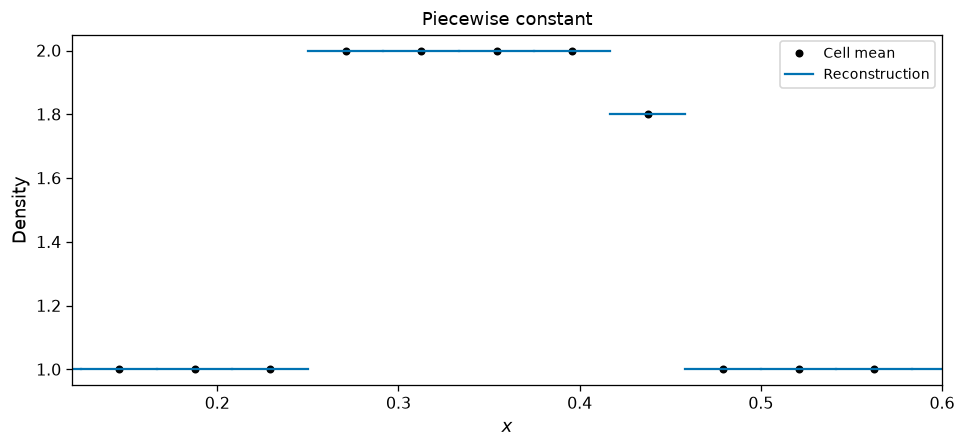

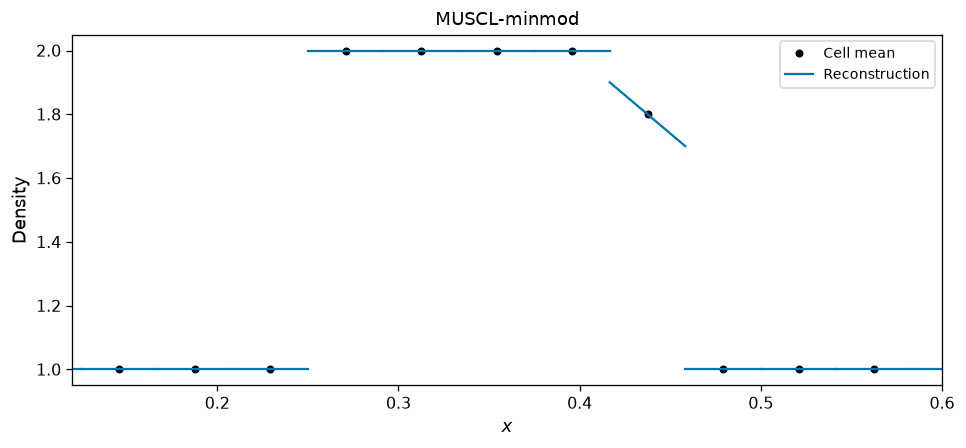

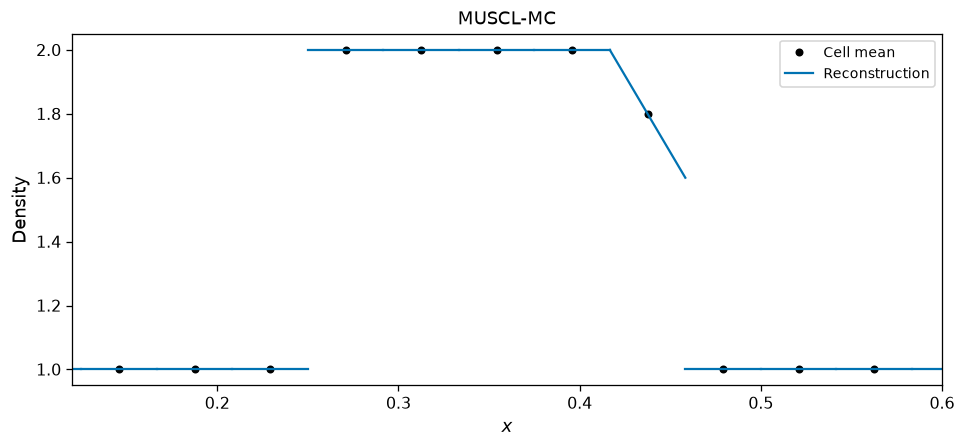

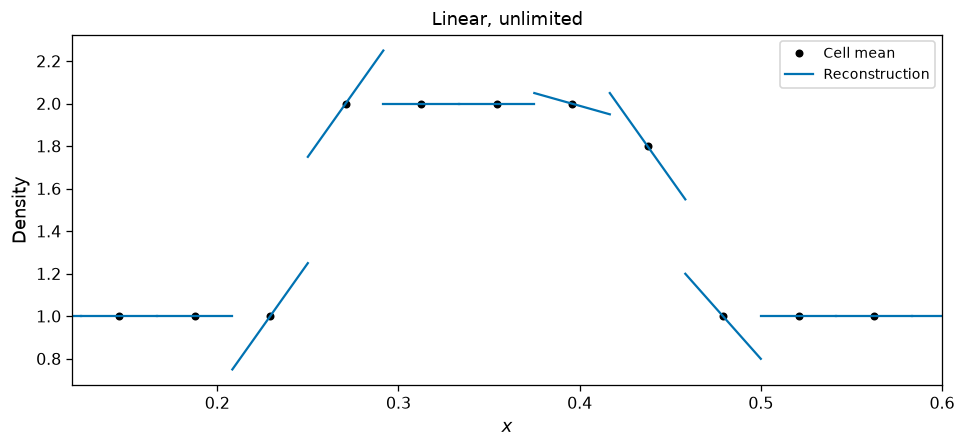

In [3]:
# 接触不連続を含むセル平均から、各セル内の線形分布を可視化する。
problem = core.PROBLEMS["contact"]
edges, centers, dx = core.grid_for(problem, 24)
U = core.initial_cell_average(problem, edges, CFG["gamma"])
for name in CFG["spatial_methods"]:
    rec, limiter = ex.SPATIAL_METHODS[name]
    UL, UR = core.interface_states(U, problem, CFG["gamma"], 1 if rec == "constant" else 2, limiter)
    left = core.cons_to_prim(UR, CFG["gamma"])[:-1, 0]
    right = core.cons_to_prim(UL, CFG["gamma"])[1:, 0]
    fig = plt.figure(figsize=(8.5, 4.0))
    ax = fig.gca()
    ax.plot(centers, U[:, 0], "o", color="#000000", ms=4, label="Cell mean")
    for i in range(len(centers)):
        ax.plot(edges[i:i+2], [left[i], right[i]], color="#0072B2", lw=1.4, label="Reconstruction" if i == 0 else None)
    ax.set(xlabel="$x$", ylabel="Density", xlim=(0.12, 0.6), title=ex.SPATIAL_LABELS[name])
    ax.legend()
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## 3. 時間積分を固定する

$\mathcal E_{\Delta t}(U)=U+\Delta t\,\mathcal L(U)$ と定義すると、SSP-RK2は

$$U^{(1)}=\mathcal E_{\Delta t}(U^n),\qquad U^{n+1}=\tfrac12U^n+\tfrac12\mathcal E_{\Delta t}(U^{(1)}).$$

各段階で境界条件、再構築、数値流束を計算し直します。ここではこの式を共通の道具として使います。前進EulerやSSP-RK3との違いは第V部で調べます。[R8, T1]

**時間積分法を固定しても、時間誤差がゼロになるわけではありません。** 格子収束試験は全離散化誤差を測り、その後のCFL半減試験で時間誤差への感度を確認します。

## 4. 滑らかなエントロピー波

圧力・速度が一定で密度だけが移流します。滑らかな解での振幅・位相とセル平均誤差を比較します。

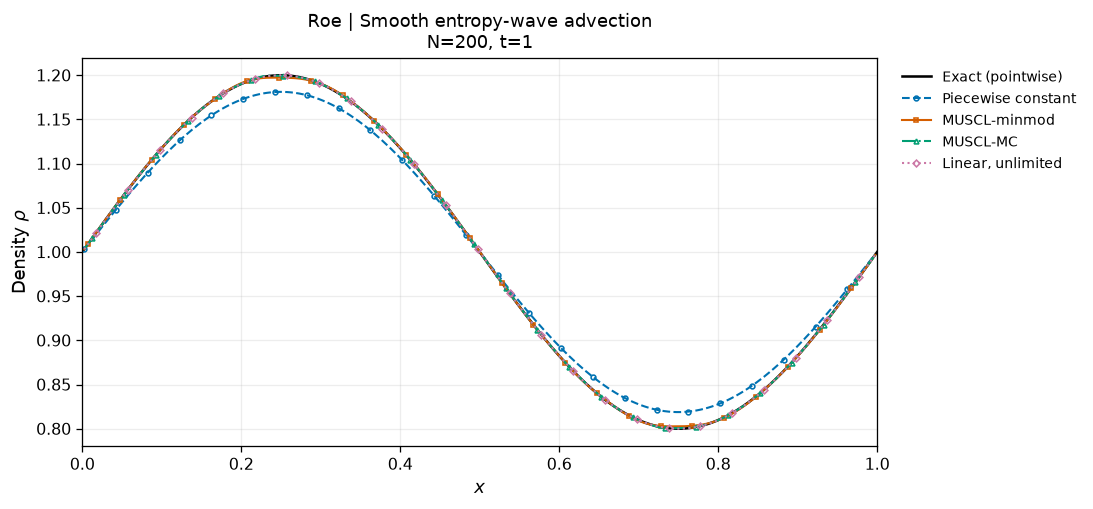

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
Roe,constant,constant,ssprk2,ok,1,0.01197,1,3.553e-15,2316,0.7033
Roe,muscl,minmod,ssprk2,ok,1,0.0005035,1,6.661e-16,2322,0.9927
Roe,muscl,mc,ssprk2,ok,1,0.000141,1,1.332e-15,2324,1.023
Roe,muscl,unlimited,ssprk2,ok,1,6.972e-05,1,8.882e-16,2324,0.9601


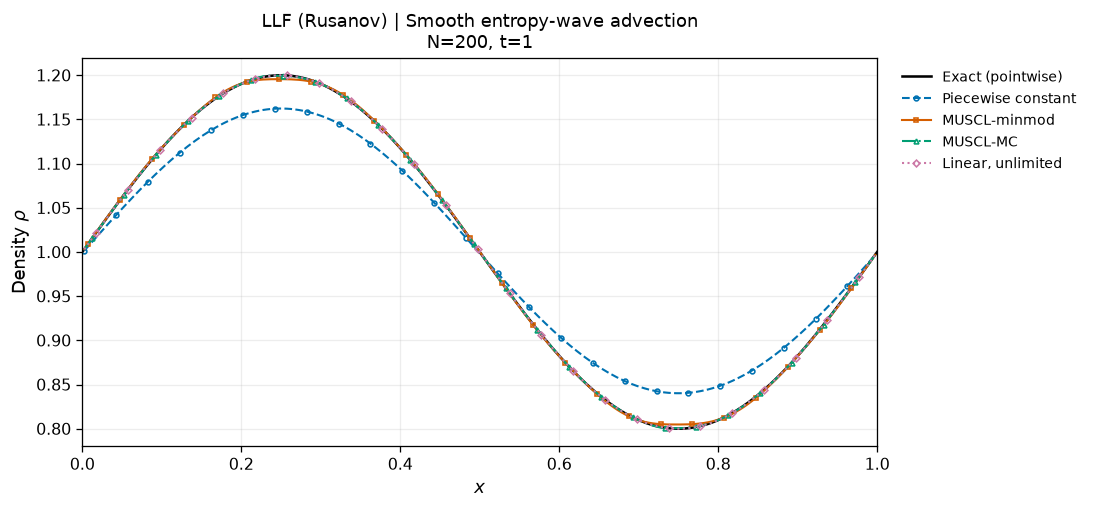

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
LLF,constant,constant,ssprk2,ok,1,0.02473,1,4.441e-16,2306,0.4761
LLF,muscl,minmod,ssprk2,ok,1,0.001034,1,1.332e-15,2322,0.7681
LLF,muscl,mc,ssprk2,ok,1,0.0001443,1,2.22e-15,2324,0.8085
LLF,muscl,unlimited,ssprk2,ok,1,6.999e-05,1,1.11e-15,2324,0.745


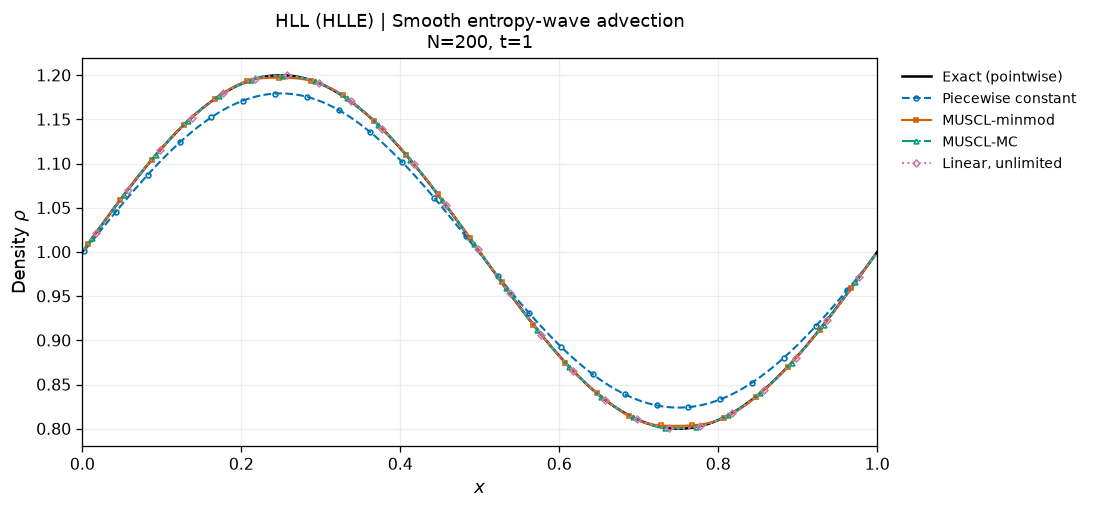

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLL,constant,constant,ssprk2,ok,1,0.0141,1,1.11e-15,2314,0.6228
HLL,muscl,minmod,ssprk2,ok,1,0.0005896,1,8.882e-16,2322,0.9015
HLL,muscl,mc,ssprk2,ok,1,0.0001418,1,1.221e-15,2324,0.9476
HLL,muscl,unlimited,ssprk2,ok,1,6.975e-05,1,1.776e-15,2324,0.8688


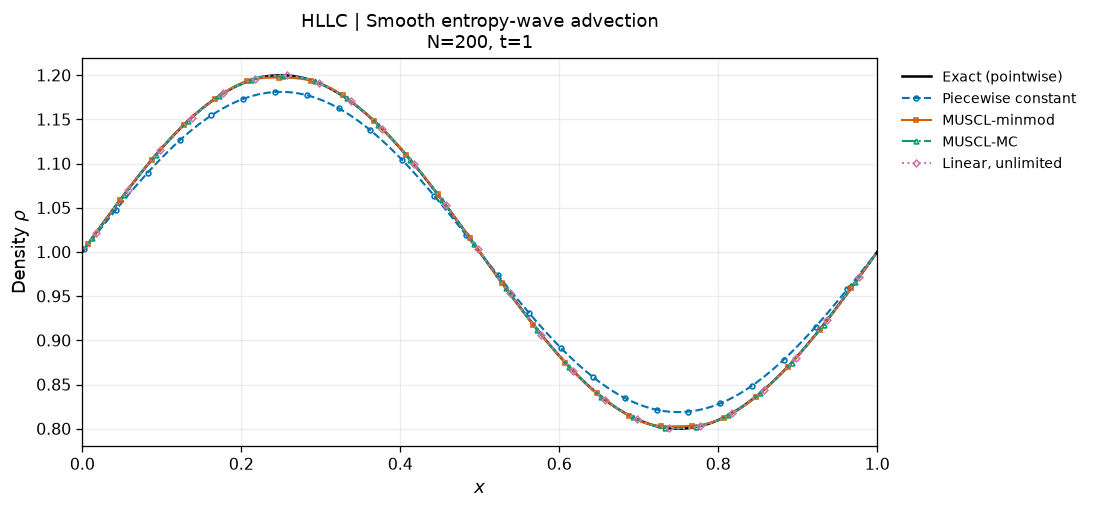

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLLC,constant,constant,ssprk2,ok,1,0.01197,1,2.22e-15,2316,0.8401
HLLC,muscl,minmod,ssprk2,ok,1,0.0005035,1,4.441e-16,2322,1.141
HLLC,muscl,mc,ssprk2,ok,1,0.000141,1,1.332e-15,2324,1.179
HLLC,muscl,unlimited,ssprk2,ok,1,6.972e-05,1,8.882e-16,2324,1.109


In [4]:
for flux in CFG["fluxes"]:
    runs = ex.group_runs("entropy", flux, CFG, "space")
    ex.plot_group(runs, "space", fields=("rho",))
    ex.summarize(runs)

## 5. 移動する接触不連続面

不連続面が広がる幅と、制限なし再構築による数値振動を比べます。最小・最大密度も確認してください。

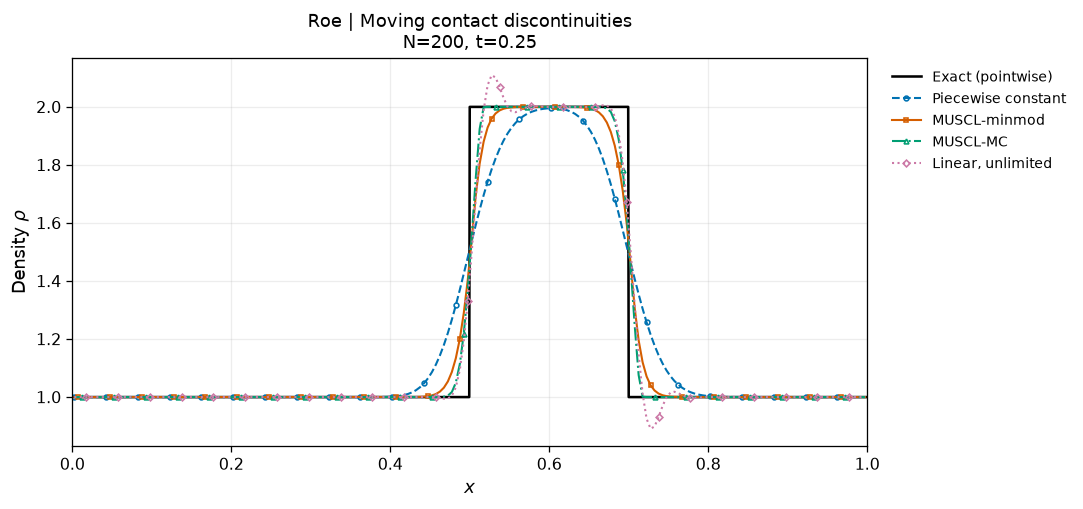

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
Roe,constant,constant,ssprk2,ok,0.25,0.05633,1,2.22e-16,546,0.1679
Roe,muscl,minmod,ssprk2,ok,0.25,0.0248,1,8.882e-16,546,0.2372
Roe,muscl,mc,ssprk2,ok,0.25,0.01546,1,0,546,0.2451
Roe,muscl,unlimited,ssprk2,ok,0.25,0.02095,1,4.441e-16,562,0.2347


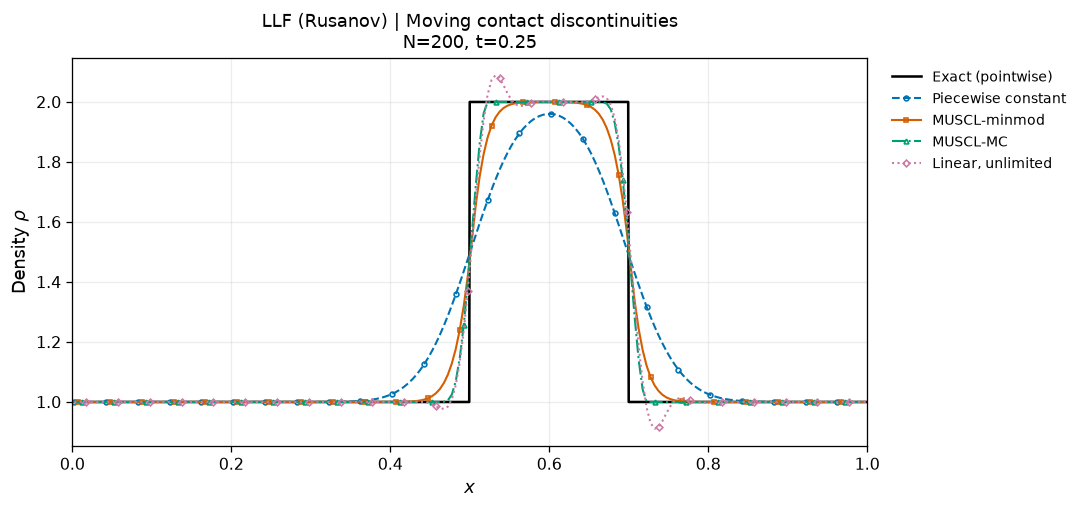

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
LLF,constant,constant,ssprk2,ok,0.25,0.07941,1,4.441e-16,546,0.1132
LLF,muscl,minmod,ssprk2,ok,0.25,0.03129,1,2.22e-15,546,0.1807
LLF,muscl,mc,ssprk2,ok,0.25,0.01812,1,0,546,0.188
LLF,muscl,unlimited,ssprk2,ok,0.25,0.02357,1,8.882e-16,560,0.1789


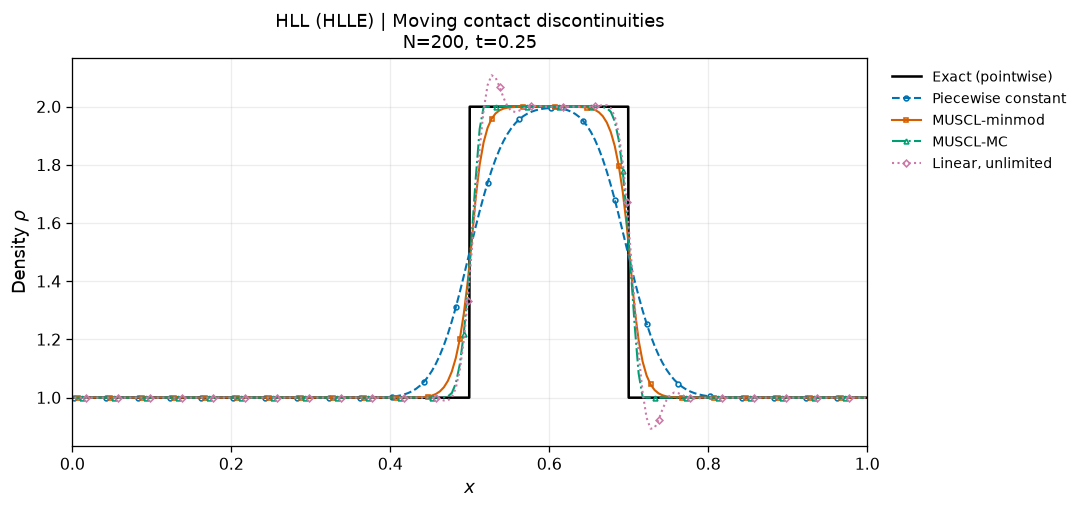

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLL,constant,constant,ssprk2,ok,0.25,0.05699,1,1.332e-15,546,0.1425
HLL,muscl,minmod,ssprk2,ok,0.25,0.02514,1,8.882e-16,546,0.2128
HLL,muscl,mc,ssprk2,ok,0.25,0.01553,1,1.776e-15,546,0.221
HLL,muscl,unlimited,ssprk2,ok,0.25,0.02115,1,1.776e-15,562,0.2107


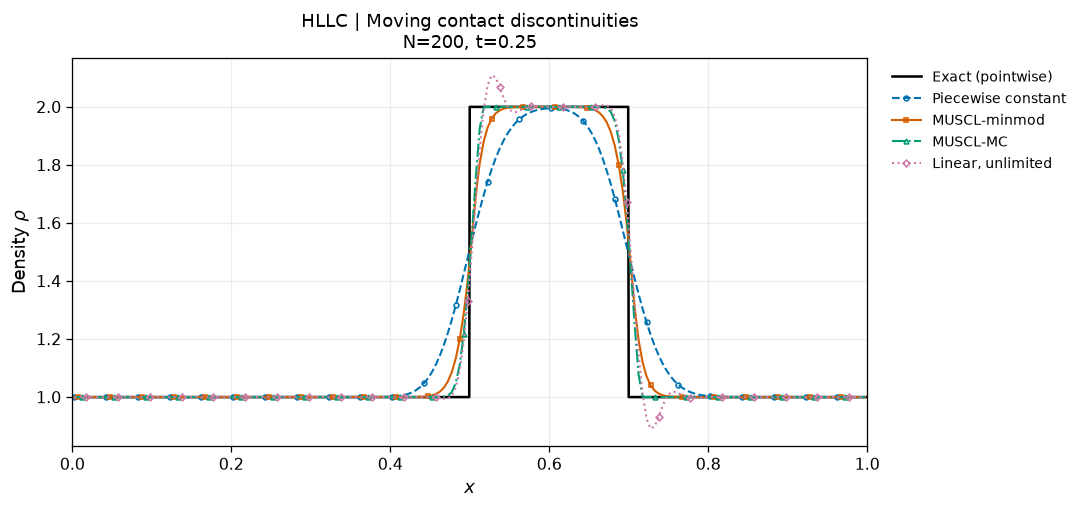

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLLC,constant,constant,ssprk2,ok,0.25,0.05633,1,8.882e-16,546,0.2142
HLLC,muscl,minmod,ssprk2,ok,0.25,0.0248,1,8.882e-16,546,0.2643
HLLC,muscl,mc,ssprk2,ok,0.25,0.01546,1,4.441e-16,546,0.2738
HLLC,muscl,unlimited,ssprk2,ok,0.25,0.02095,1,6.661e-16,562,0.2712


In [5]:
for flux in CFG["fluxes"]:
    runs = ex.group_runs("contact", flux, CFG, "space")
    ex.plot_group(runs, "space", fields=("rho",))
    ex.summarize(runs)

## 6. 静止する接触不連続面

Roe・HLLCの接触波の扱いと、再構築の役割を区別します。再構築だけで、全流束が同じ性質になるとは限りません。

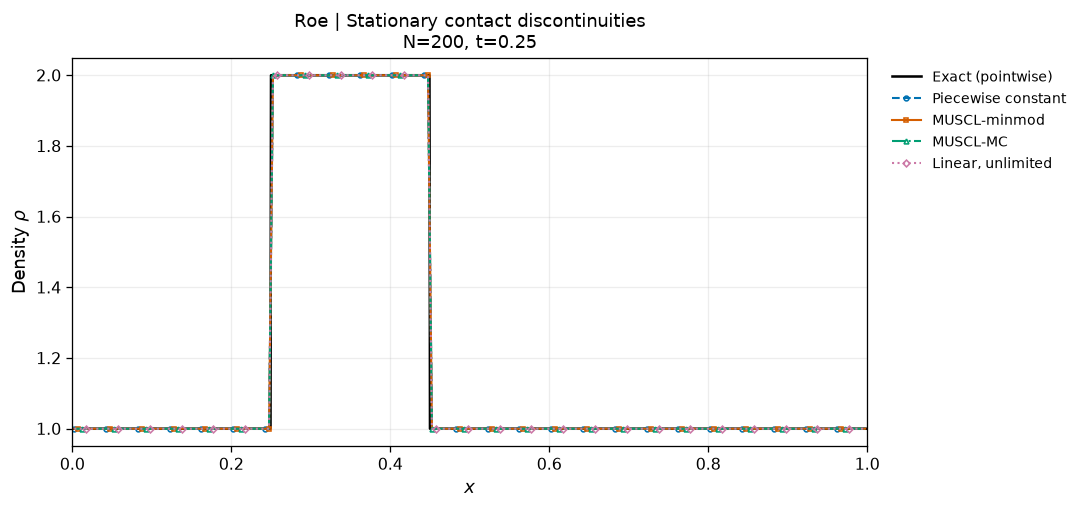

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
Roe,constant,constant,ssprk2,ok,0.25,0,1,0,296,0.106
Roe,muscl,minmod,ssprk2,ok,0.25,0,1,0,296,0.1357
Roe,muscl,mc,ssprk2,ok,0.25,0,1,0,296,0.1389
Roe,muscl,unlimited,ssprk2,ok,0.25,0,1,0,296,0.1303


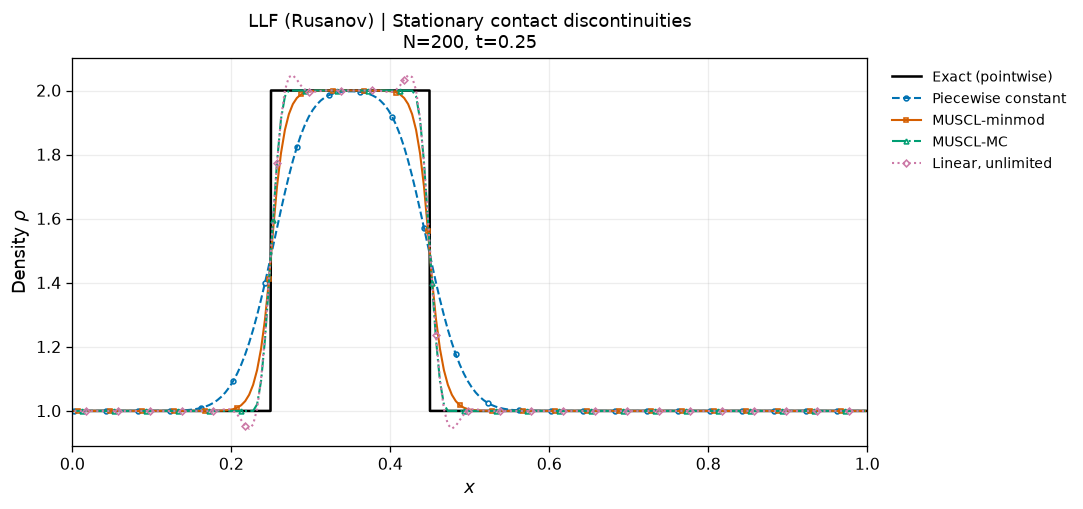

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
LLF,constant,constant,ssprk2,ok,0.25,0.05599,1,4.441e-16,296,0.0648
LLF,muscl,minmod,ssprk2,ok,0.25,0.02447,1,0,296,0.09933
LLF,muscl,mc,ssprk2,ok,0.25,0.01479,1,0,296,0.1019
LLF,muscl,unlimited,ssprk2,ok,0.25,0.01832,1,0,304,0.09878


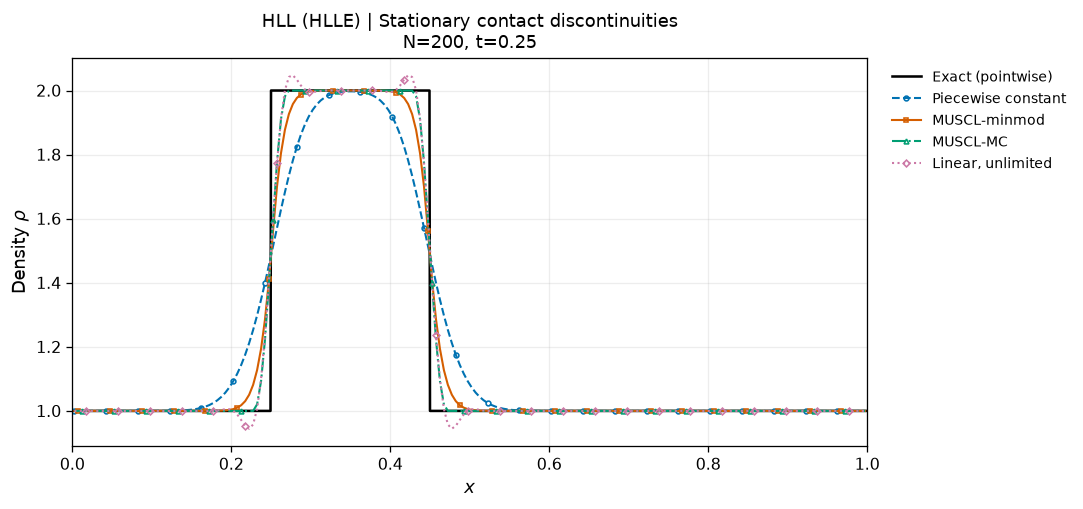

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLL,constant,constant,ssprk2,ok,0.25,0.05578,1,4.441e-16,296,0.07811
HLL,muscl,minmod,ssprk2,ok,0.25,0.02444,1,0,296,0.1157
HLL,muscl,mc,ssprk2,ok,0.25,0.01478,1,0,296,0.1189
HLL,muscl,unlimited,ssprk2,ok,0.25,0.01832,1,0,304,0.1146


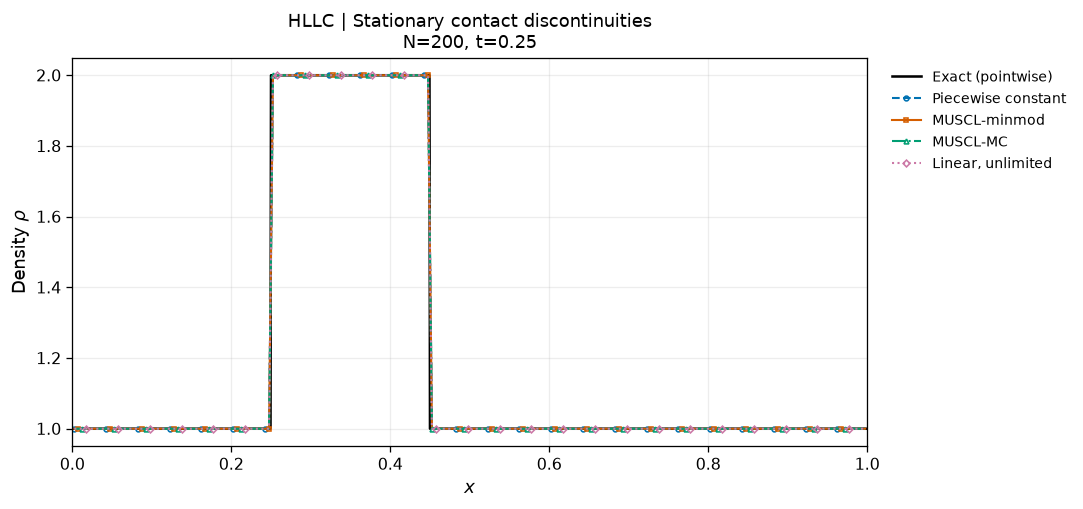

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLLC,constant,constant,ssprk2,ok,0.25,0,1,0,296,0.1076
HLLC,muscl,minmod,ssprk2,ok,0.25,0,1,0,296,0.145
HLLC,muscl,mc,ssprk2,ok,0.25,0,1,0,296,0.148
HLLC,muscl,unlimited,ssprk2,ok,0.25,0,1,0,296,0.1409


In [6]:
for flux in CFG["fluxes"]:
    runs = ex.group_runs("contact_static", flux, CFG, "space")
    ex.plot_group(runs, "space", fields=("rho",))
    ex.summarize(runs)

## 7. Sod衝撃波管

密度・圧力を比べ、接触面と衝撃波を区別します。制限なし再構築が負の境界密度などを作った場合は、計算を止めて記録します。

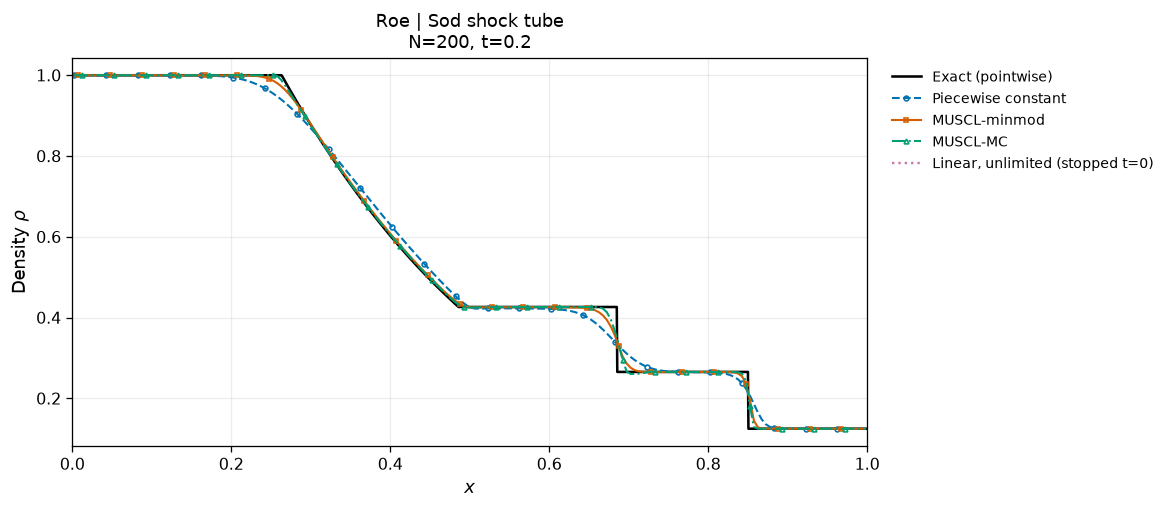

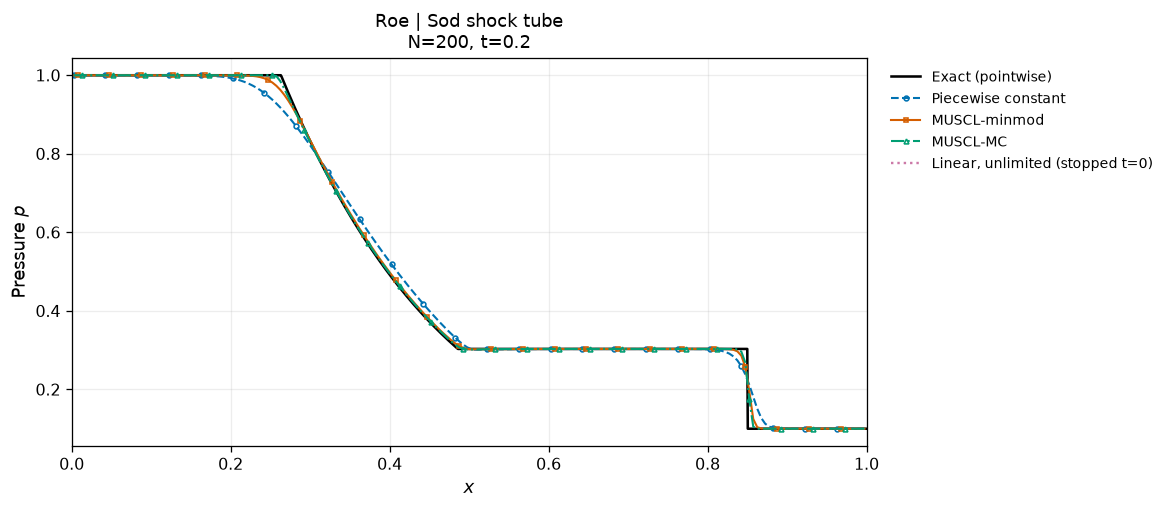

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
Roe,constant,constant,ssprk2,ok,0.2,0.01294,0.1,9.424e-16,430,0.1362
Roe,muscl,minmod,ssprk2,ok,0.2,0.003984,0.1,4.441e-16,436,0.1908
Roe,muscl,mc,ssprk2,ok,0.2,0.002206,0.1,4.441e-16,438,0.1982
Roe,muscl,unlimited,ssprk2,failed,0,—,0.1,0,1,0.0001373


Roe | MUSCL (unlimited) | SSP-RK2: MUSCL reconstruction: A reconstructed rho or p is not positive. min(rho)=nan, min(p)=nan


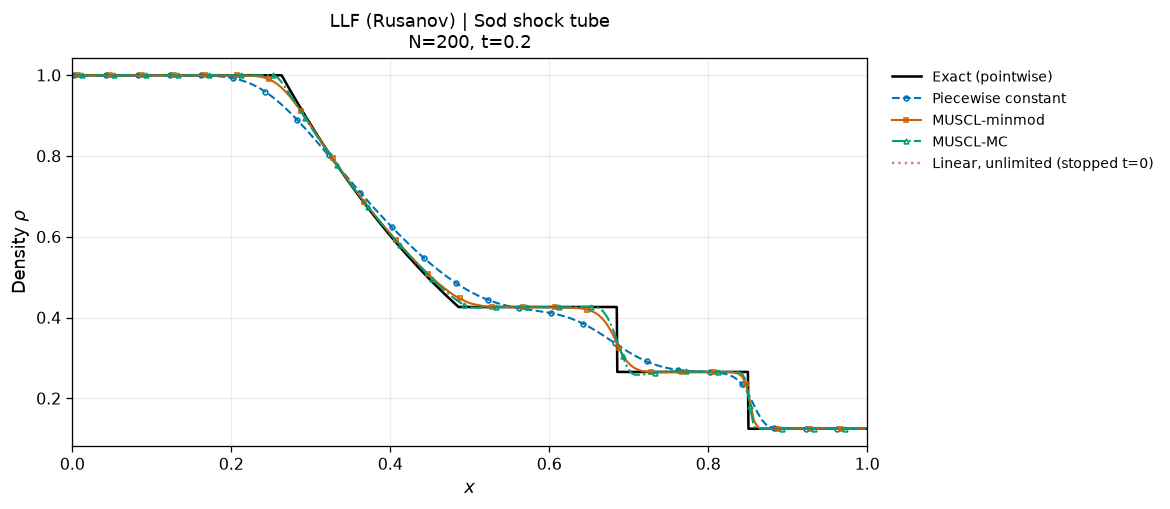

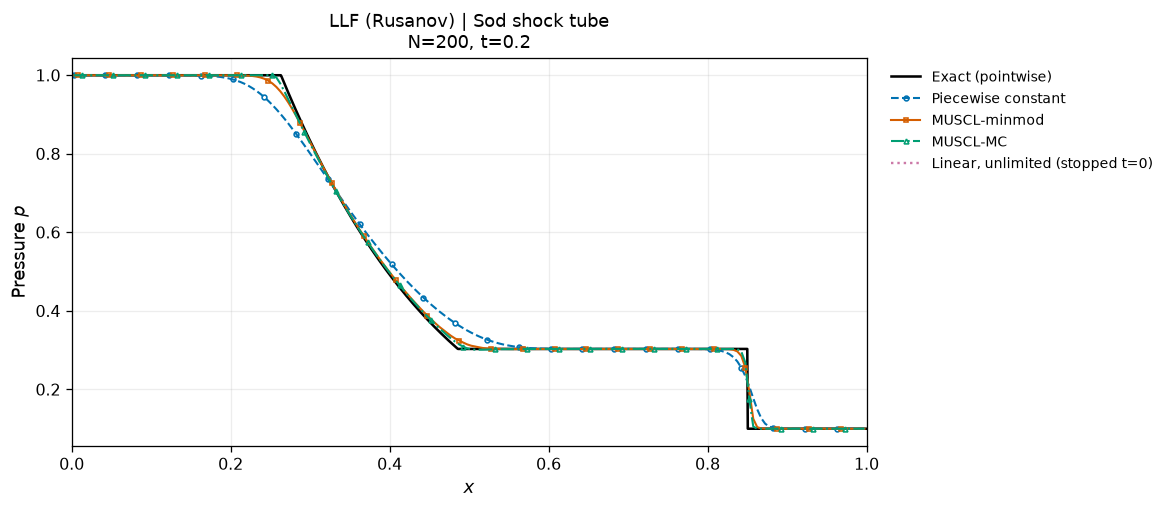

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
LLF,constant,constant,ssprk2,ok,0.2,0.01811,0.1,1.445e-16,424,0.09045
LLF,muscl,minmod,ssprk2,ok,0.2,0.005112,0.1,4.441e-16,434,0.1464
LLF,muscl,mc,ssprk2,ok,0.2,0.00333,0.1,1.11e-16,438,0.1524
LLF,muscl,unlimited,ssprk2,failed,0,—,0.1,0,1,0.0001349


LLF (Rusanov) | MUSCL (unlimited) | SSP-RK2: MUSCL reconstruction: A reconstructed rho or p is not positive. min(rho)=nan, min(p)=nan


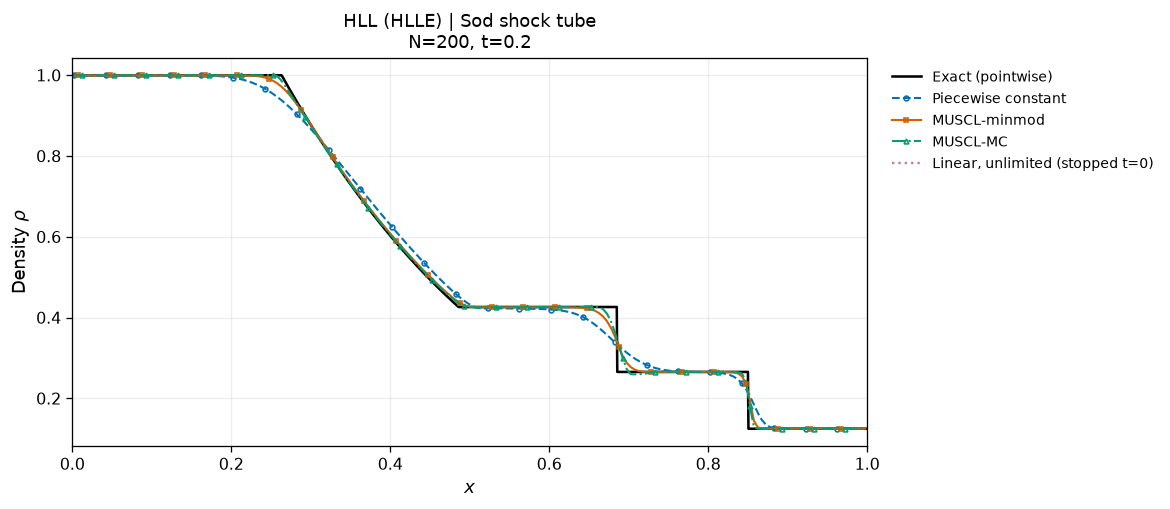

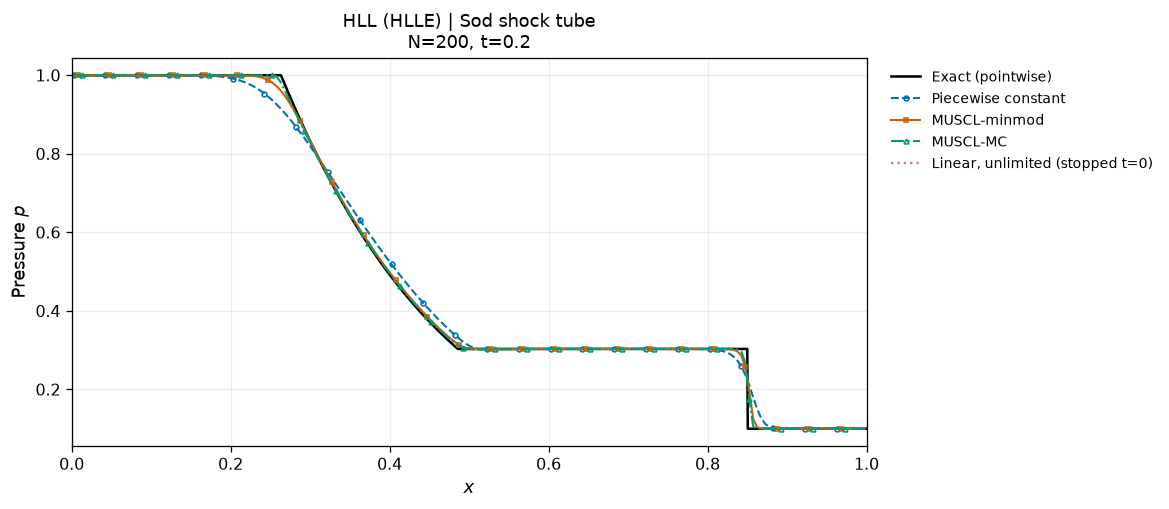

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLL,constant,constant,ssprk2,ok,0.2,0.01376,0.1,5.253e-16,428,0.1151
HLL,muscl,minmod,ssprk2,ok,0.2,0.004209,0.1,2.22e-16,434,0.2152
HLL,muscl,mc,ssprk2,ok,0.2,0.002568,0.1,4.441e-16,438,0.1816
HLL,muscl,unlimited,ssprk2,failed,0,—,0.1,0,1,0.0001343


HLL (HLLE) | MUSCL (unlimited) | SSP-RK2: MUSCL reconstruction: A reconstructed rho or p is not positive. min(rho)=nan, min(p)=nan


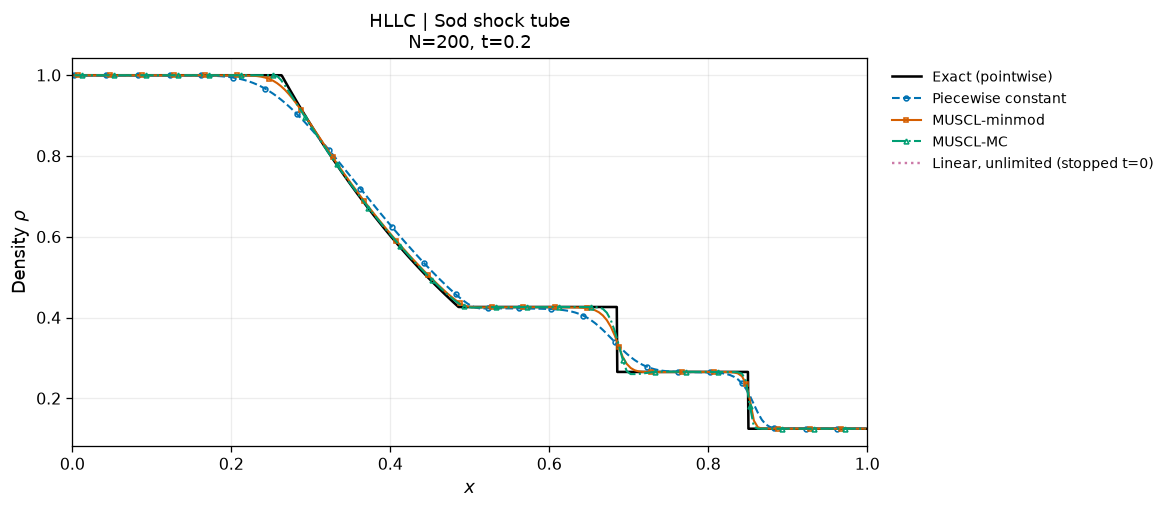

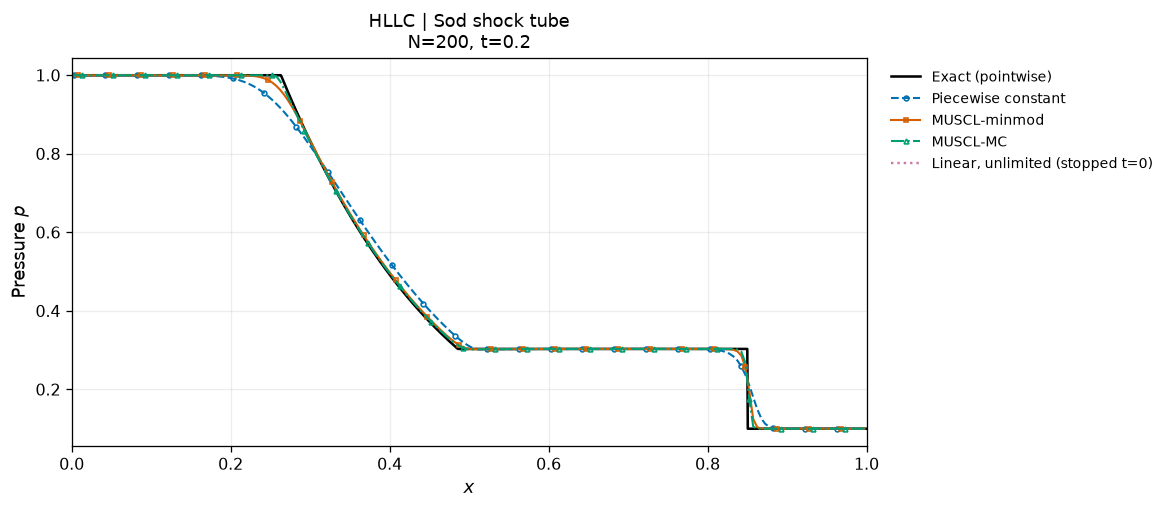

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLLC,constant,constant,ssprk2,ok,0.2,0.01318,0.1,1.965e-16,428,0.1574
HLLC,muscl,minmod,ssprk2,ok,0.2,0.004069,0.1,4.441e-16,436,0.2157
HLLC,muscl,mc,ssprk2,ok,0.2,0.002428,0.1,4.441e-16,438,0.2221
HLLC,muscl,unlimited,ssprk2,failed,0,—,0.1,0,1,0.0001359


HLLC | MUSCL (unlimited) | SSP-RK2: MUSCL reconstruction: A reconstructed rho or p is not positive. min(rho)=nan, min(p)=nan


In [7]:
for flux in CFG["fluxes"]:
    runs = ex.group_runs("sod", flux, CFG, "space")
    ex.plot_group(runs, "space", fields=("rho", "p"))
    ex.summarize(runs)

## 8. 格子収束と時間刻みへの感度

滑らかなエントロピー波について格子数を増やします。観測次数は隣接する2解像度の誤差比から求めます。
minmod・MCでは極値近傍での制限のため、観測次数を常に整数とみなさないでください。
CFL半減試験では、解の変化量を細かい時間刻みの全誤差で割った `change_over_error` も表示します。
この値が大きい場合は、空間だけの効果と解釈せず、CFL数をさらに下げて確認してください。

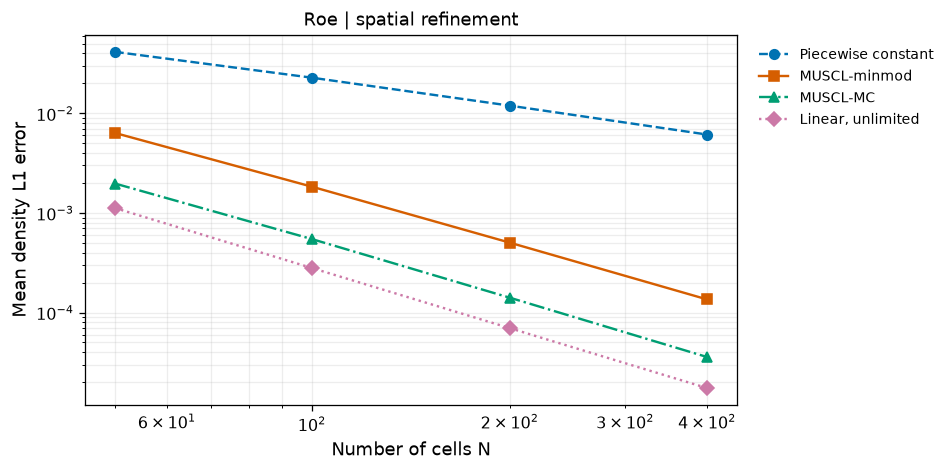

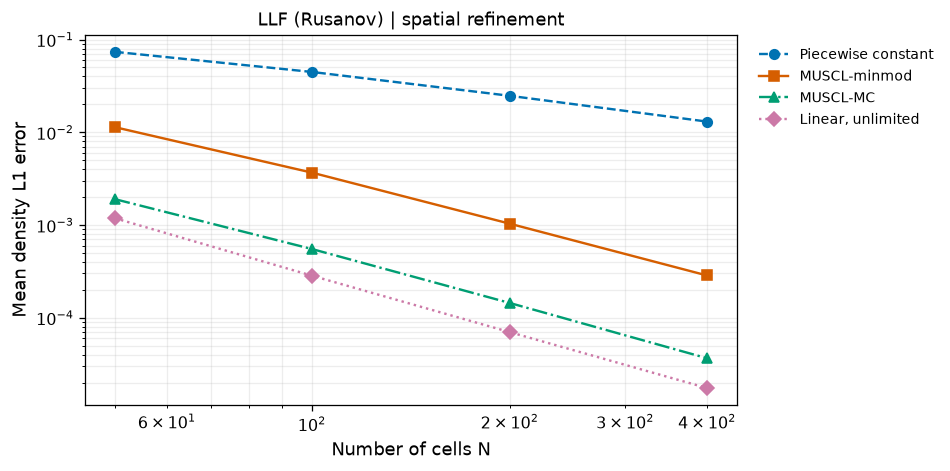

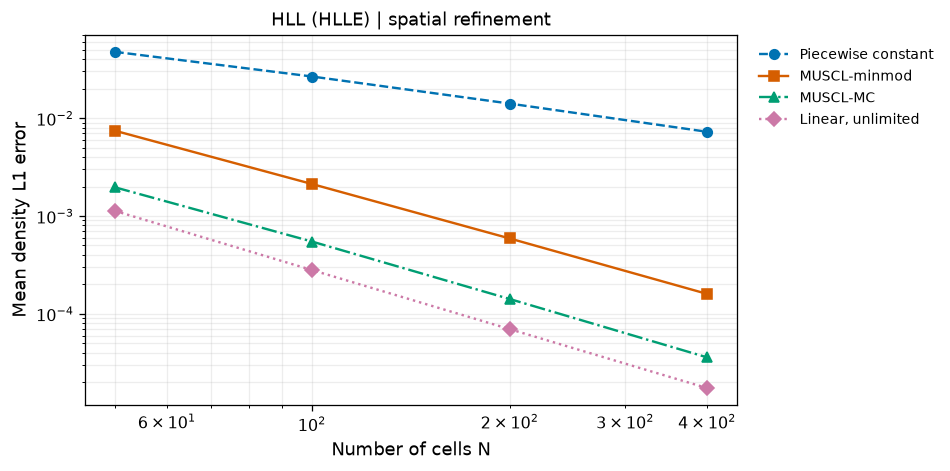

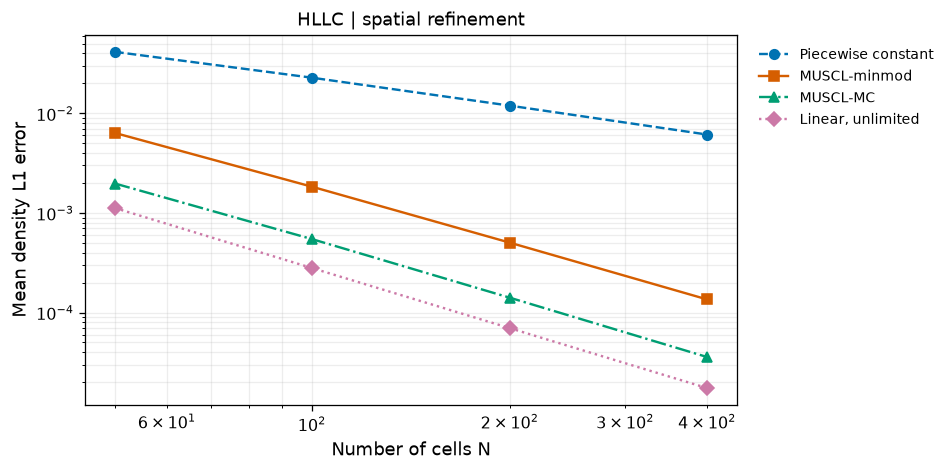

flux,reconstruction,n,L1_rho,q_observed,time_integrator
Roe,constant,50,0.0415,—,ssprk2
Roe,constant,100,0.0228,0.864,ssprk2
Roe,constant,200,0.01197,0.9303,ssprk2
Roe,constant,400,0.006131,0.9648,ssprk2
Roe,muscl_minmod,50,0.006362,—,ssprk2
Roe,muscl_minmod,100,0.001831,1.797,ssprk2
Roe,muscl_minmod,200,0.0005035,1.862,ssprk2
Roe,muscl_minmod,400,0.0001354,1.894,ssprk2
Roe,muscl_mc,50,0.001976,—,ssprk2
Roe,muscl_mc,100,0.000545,1.858,ssprk2


flux,reconstruction,density_change,fine_dt_total_error,change_over_error
Roe,constant,2.668e-06,0.01197,0.0002229
Roe,muscl_minmod,8.443e-06,0.0005028,0.01679
Roe,muscl_mc,5.448e-06,0.0001358,0.04012
Roe,linear_unlimited,2.925e-06,6.679e-05,0.04379
LLF (Rusanov),constant,2.393e-06,0.02473,9.678e-05
LLF (Rusanov),muscl_minmod,5.805e-06,0.001033,0.005619
LLF (Rusanov),muscl_mc,5.47e-06,0.000139,0.03934
LLF (Rusanov),linear_unlimited,2.925e-06,6.707e-05,0.04361
HLL (HLLE),constant,2.618e-06,0.0141,0.0001856
HLL (HLLE),muscl_minmod,7.067e-06,0.000589,0.012


In [8]:
if CFG["run_convergence"]:
    TABLES["spatial_convergence"] = ex.spatial_convergence(CFG)
if CFG["run_time_check"]:
    TABLES["time_sensitivity"] = ex.spatial_time_check(CFG)

## 9. 低密度・低圧力での頑健性

二重希薄波を用います。どこで計算が停止したか、最後の受理時刻と停止理由を調べます。
エントロピー補正と正値性対策は異なるものです。1次精度で完走する流束でも、高次再構築を組み合わせた任意の条件に対する正値性保証を意味しません。

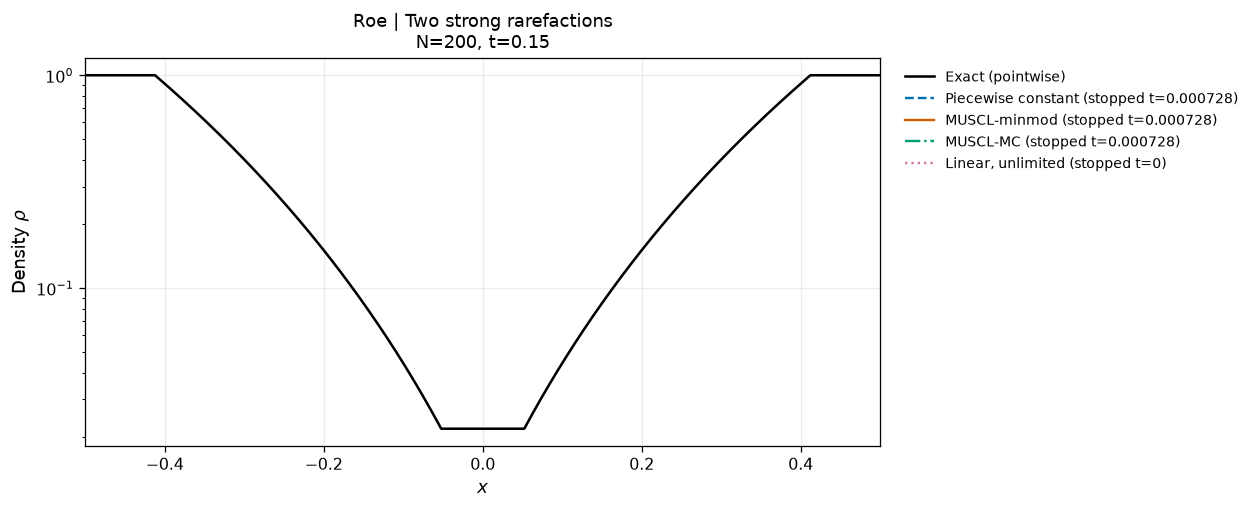

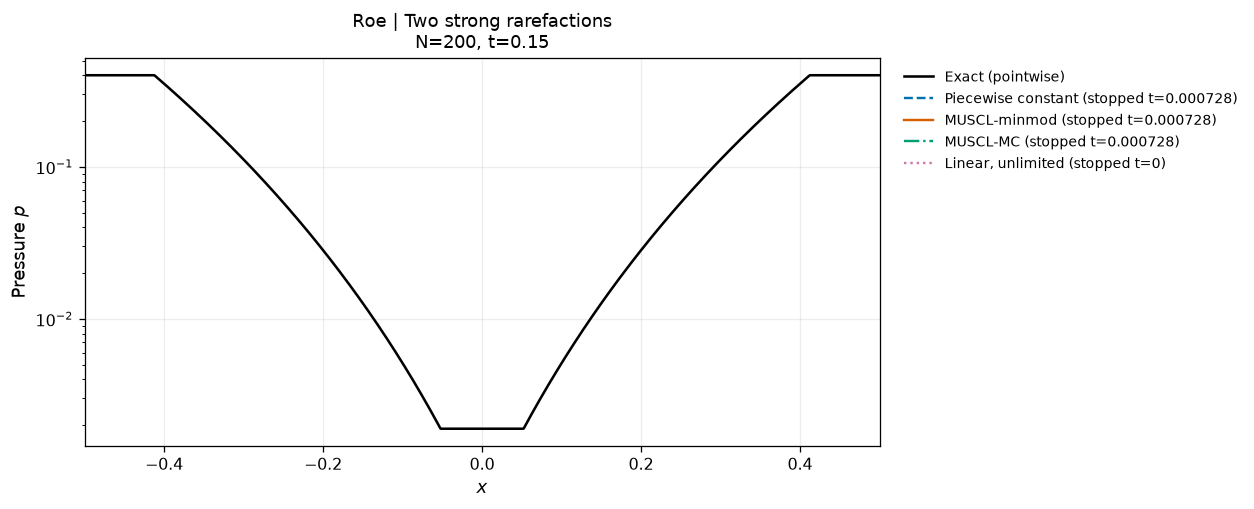

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
Roe,constant,constant,ssprk2,failed,0.0007277,—,0.07465,4.901e-17,3,0.001664
Roe,muscl,minmod,ssprk2,failed,0.0007277,—,0.07465,4.901e-17,3,0.001549
Roe,muscl,mc,ssprk2,failed,0.0007277,—,0.07465,4.901e-17,3,0.001509
Roe,muscl,unlimited,ssprk2,failed,0,—,0.4,0,1,0.0005146


Roe | Piecewise constant | SSP-RK2: RK stage 1:  min(rho)=4.86088e-01, min(p)=-2.76703e-01
Roe | MUSCL (minmod) | SSP-RK2: RK stage 1:  min(rho)=4.86088e-01, min(p)=-2.76703e-01
Roe | MUSCL (mc) | SSP-RK2: RK stage 1:  min(rho)=4.86088e-01, min(p)=-2.76703e-01
Roe | MUSCL (unlimited) | SSP-RK2: RK stage 1:  min(rho)=5.63371e-01, min(p)=-8.78513e-03


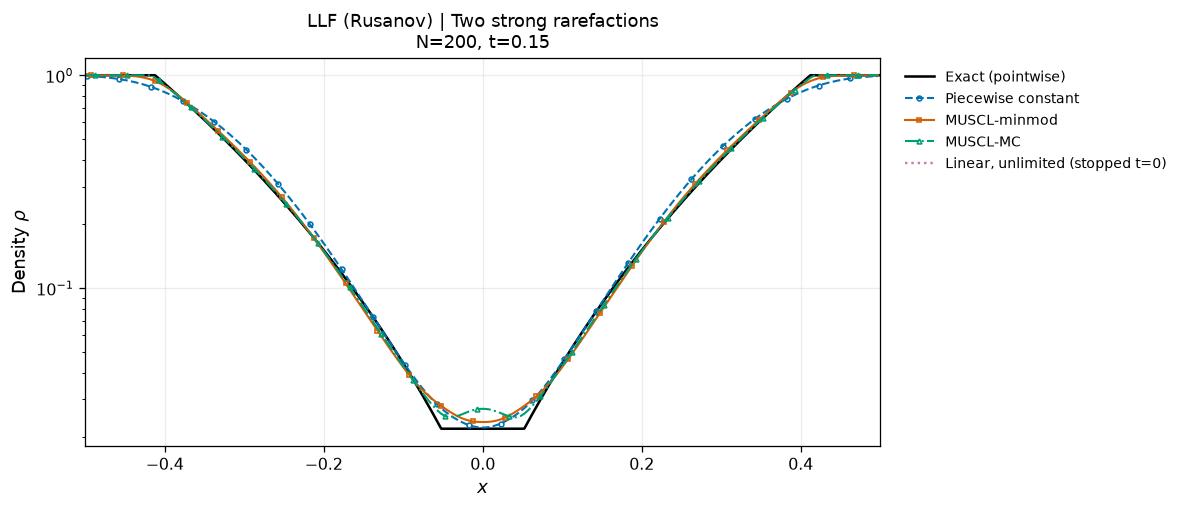

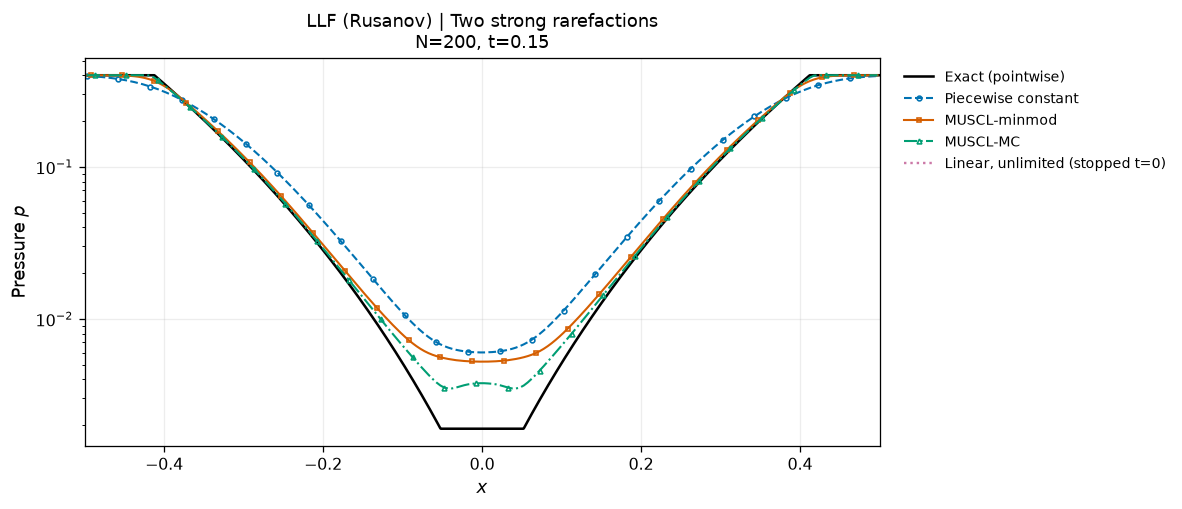

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
LLF,constant,constant,ssprk2,ok,0.15,0.02735,0.006013,4.441e-16,414,0.08949
LLF,muscl,minmod,ssprk2,ok,0.15,0.00803,0.00523,3.553e-15,414,0.1403
LLF,muscl,mc,ssprk2,ok,0.15,0.003291,0.003481,4.885e-15,414,0.1473
LLF,muscl,unlimited,ssprk2,failed,0,—,0.4,0,2,0.000481


LLF (Rusanov) | MUSCL (unlimited) | SSP-RK2: MUSCL reconstruction: A reconstructed rho or p is not positive. min(rho)=nan, min(p)=nan


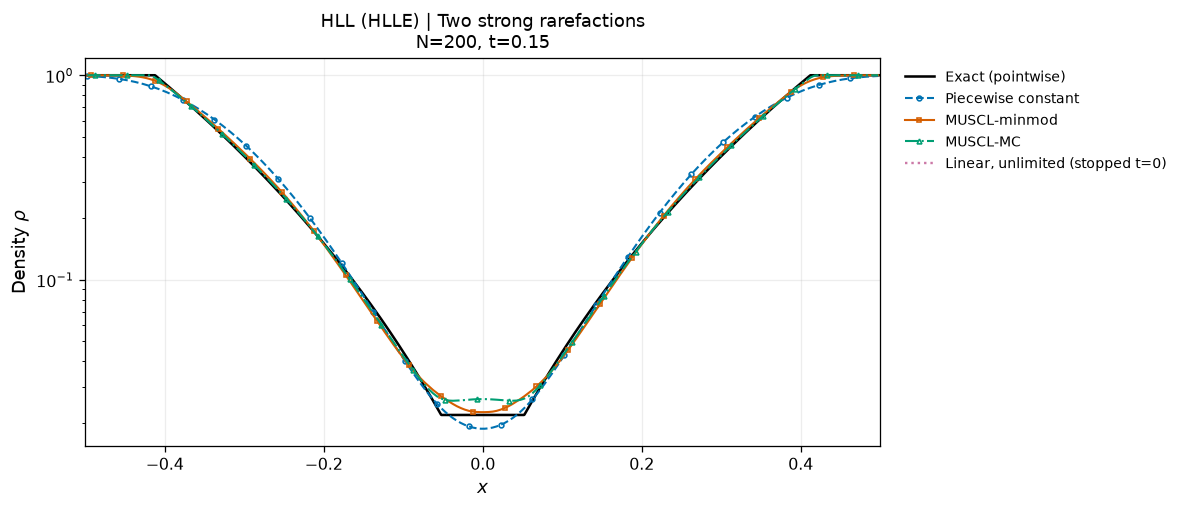

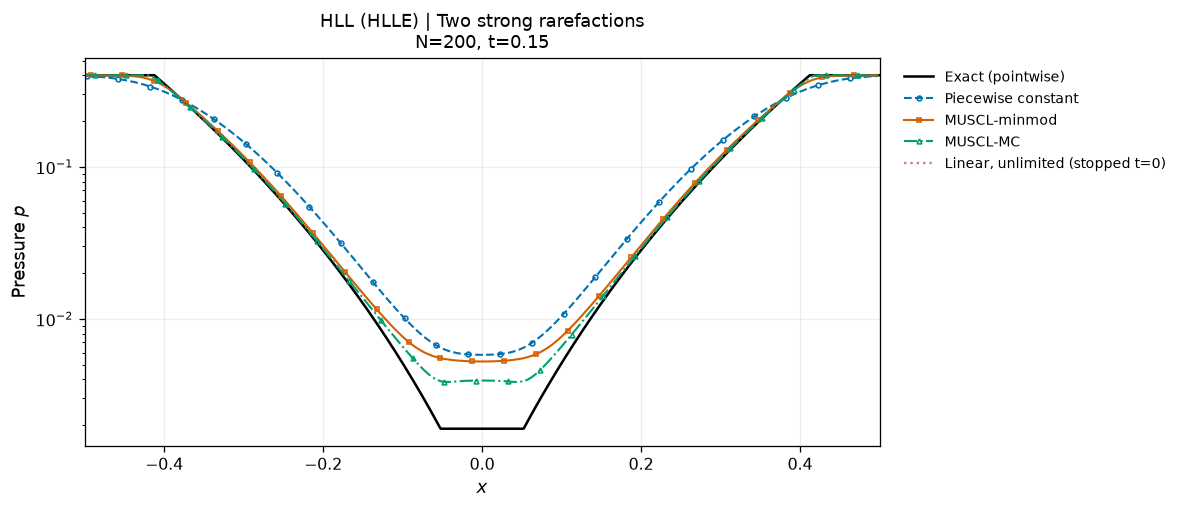

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLL,constant,constant,ssprk2,ok,0.15,0.02836,0.005798,8.882e-16,414,0.1117
HLL,muscl,minmod,ssprk2,ok,0.15,0.008087,0.005241,2.22e-15,414,0.1662
HLL,muscl,mc,ssprk2,ok,0.15,0.003317,0.003845,4.885e-15,414,0.1684
HLL,muscl,unlimited,ssprk2,failed,0,—,0.4,0,2,0.0004999


HLL (HLLE) | MUSCL (unlimited) | SSP-RK2: MUSCL reconstruction: A reconstructed rho or p is not positive. min(rho)=nan, min(p)=nan


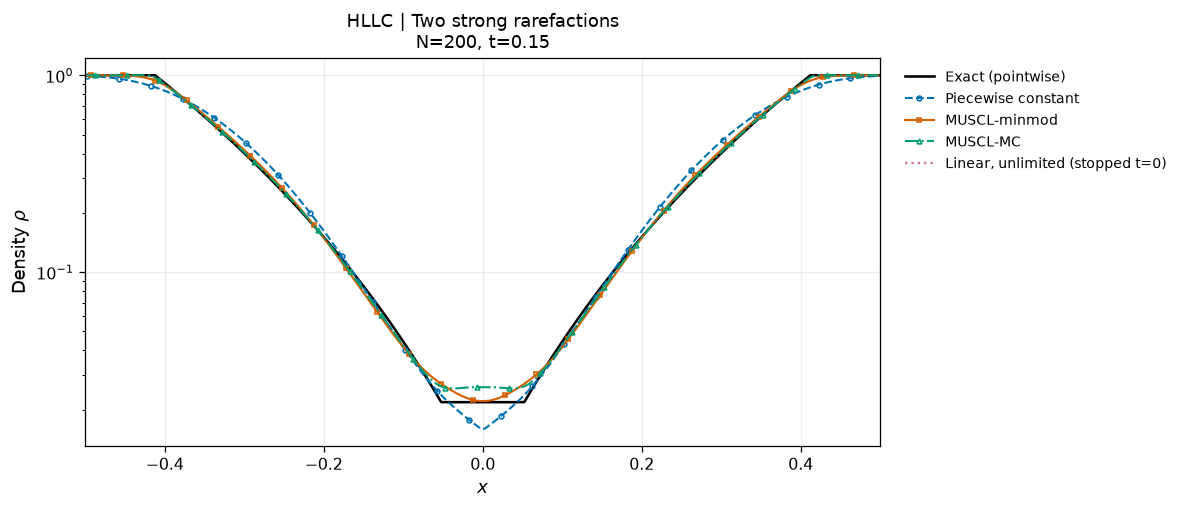

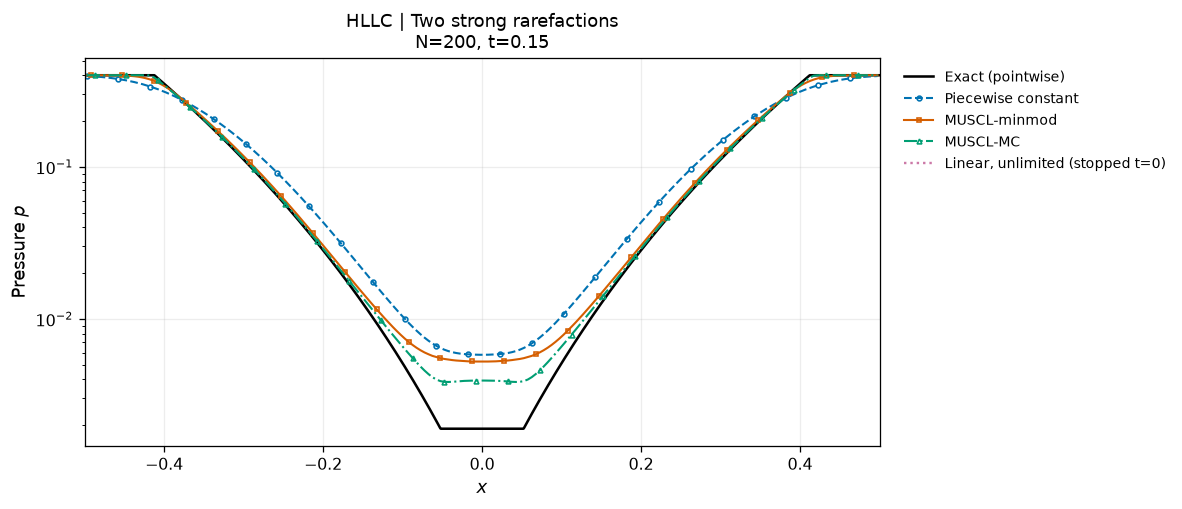

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLLC,constant,constant,ssprk2,ok,0.15,0.02844,0.005803,1.332e-15,414,0.1421
HLLC,muscl,minmod,ssprk2,ok,0.15,0.008081,0.005235,1.776e-15,414,0.1956
HLLC,muscl,mc,ssprk2,ok,0.15,0.003317,0.003844,4.441e-15,414,0.2017
HLLC,muscl,unlimited,ssprk2,failed,0,—,0.4,0,2,0.0006049


HLLC | MUSCL (unlimited) | SSP-RK2: MUSCL reconstruction: A reconstructed rho or p is not positive. min(rho)=nan, min(p)=nan


In [9]:
if CFG["run_robustness"]:
    for flux in CFG["fluxes"]:
        runs = ex.group_runs("double_rarefaction", flux, CFG, "space")
        ex.plot_group(runs, "space", fields=("rho", "p"))
        ex.summarize(runs)

## 10. 時間発展の動画

`movie_problem`、`movie_fluxes`、`movie_field` は設定セル直前の表から選びます。
同じ流束の中で空間再構築を比較します。フレーム時刻だけを共通化し、受理済み保存状態を表示用に線形補間します。補間状態を時間積分へ戻しません。
軸は固定し、停止した方式は停止時刻より後には描きません。JavaScript表示なのでffmpegは不要です。

In [10]:
if CFG["run_movies"]:
    for flux in CFG["movie_fluxes"]:
        fig, movie = ex.comparison_movie(CFG["movie_problem"], flux, CFG, "space")
        display(HTML(movie.to_jshtml()))
        plt.close(fig)

## 11. 発展実験と結果保存

`run_shu_osher=True` では、HLLC＋MUSCL-MC＋SSP-RK2の2解像度の参照計算も行います。黒線は数値参照解で、厳密解ではありません。[R5]
`run_extras=True` はLax衝撃波管を追加します。結果はCSV・NPZ・JSONとして保存します。
**問い：** 同じ流束でminmodとMCを変更した差は、流束を変更した差に比べてどの程度大きいでしょうか。

In [11]:
if CFG["run_extras"]:
    for flux in CFG["fluxes"]:
        runs = ex.group_runs("lax", flux, CFG, "space")
        ex.plot_group(runs, "space")
        ex.summarize(runs)
if CFG["run_shu_osher"]:
    reference = shu_reference(CFG)
    for flux in CFG["fluxes"]:
        runs = ex.group_runs("shu_osher", flux, CFG, "space", n=CFG["n_shu_osher"])
        ex.plot_group(runs, "space", reference=reference)
        ex.summarize(runs, reference=reference)
if CFG["export_results"]:
    saved_rows = ex.export_results(OUTPUT_DIR, CFG, TABLES, reference=reference)

Saved 144 runs: /home/runner/work/euler1d-scheme-comparison/euler1d-scheme-comparison/five_part_outputs/spatial


## まとめ

空間再構築は数値流束への入力となる左右状態を決めます。高次再構築と低散逸な流束は同じものではありません。
勾配制限は振動を抑えるための工夫ですが、局所精度の低下も伴います。制限なし再構築は衝撃波計算の推奨設定ではなく、リミッターの必要性を学ぶ比較例です。

[第V部](05_time_integration.ipynb)では空間再構築を固定し、前進Euler・SSP-RK2・SSP-RK3を比較します。PPM・WENOは本教材の実装範囲には含めません。

## 参考文献・実装の確認先

以下は原論文または開発者による公式資料です。Notebookのコードはこれらの数式・考え方を参考に、本教材用に組み立てた実装であり、Clawpack等を呼び出してはいません。

**[R1]** Clawpack, *The Euler equations of gas dynamics*：波の構造と厳密リーマン解。  
https://www.clawpack.org/riemann_book/html/Euler.html

**[R2]** Clawpack, *Approximate solvers for the Euler equations of gas dynamics*：Roe平均、HLLEの波速推定、低密度問題。  
https://www.clawpack.org/riemann_book/html/Euler_approximate.html

**[R3]** Clawpack, *Riemann Solver Package — Euler Equations*：HLLCの接触波速度と中間状態。  
https://www.clawpack.org/pyclaw/rp.html#euler-equations

**[R4]** FLASH User's Guide, *Hydrodynamics Test Problems*, §35.1.1：Sod問題と波面の位置。  
https://flash.rochester.edu/site/flashcode/user_support/flash_ug_devel/node191.html

**[R5]** Clawpack Gallery, *Shu–Osher problem*：初期状態、領域、終了時刻。  
https://www.clawpack.org/gallery/pyclaw/gallery/shocksine.html

**[R6]** Toro, E. F., Spruce, M., & Speares, W. (1994), *Restoration of the contact surface in the HLL-Riemann solver*, Shock Waves, 4, 25–34.  
https://doi.org/10.1007/BF01414629

**[R7]** Harten, A. (1983), *High resolution schemes for hyperbolic conservation laws*, Journal of Computational Physics, 49, 357–393.  
https://doi.org/10.1016/0021-9991(83)90136-5

**[R8]** Shu, C.-W., & Osher, S. (1988), *Efficient implementation of essentially non-oscillatory shock-capturing schemes*, Journal of Computational Physics, 77, 439–471.  
https://doi.org/10.1016/0021-9991(88)90177-5

**[R9]** Shu, C.-W., & Osher, S. (1989), *Efficient implementation of essentially non-oscillatory shock-capturing schemes, II*, Journal of Computational Physics, 83, 32–78.  
https://doi.org/10.1016/0021-9991(89)90222-2

初期条件・波速推定・エントロピー補正・リミッター・CFL数まで含めて、比較の設定を報告することが重要です。
「Roe」や「HLLC」という名前だけでは、実装のすべては決まりません。

**[T1]** Gkeyll developers, *Strong-Stability preserving Runge-Kutta time-steppers*：SSP-RK2・3段階SSP-RK3の更新式。
https://gkeyll.readthedocs.io/en/latest/dev/ssp-rk.html

**[T2]** Gottlieb, S., Shu, C.-W., & Tadmor, E. (2001), *Strong Stability-Preserving High-Order Time Discretization Methods*, SIAM Review, 43, 89–112.
https://doi.org/10.1137/S003614450036757X